# E-Commerce Customer Purchase Prediction Using Logistic Regression

**Organization:** Sapphire IQ (LMS Project)  |  **Company Name:** ShopSmart  |  **Domain:** E-Commerce  
**Dataset Size:** 10,000 Records  |  **Learning Type:** Supervised Learning  |  **ML Category:** Classification (Binary Classification)  |  **Algorithm Used:** Logistic Regression

---

### Problem Statement
E-commerce platforms generate massive amounts of customer interaction data every day, yet many visitors browse products without completing a purchase. **ShopSmart**, a growing online retail company, wants to understand customer purchasing patterns and predict whether a visitor will complete a purchase during their session (`Purchase`: `1` = Purchase, `0` = No Purchase) using historical browsing behaviour, cart details, customer engagement, and demographic attributes.

### Alignment with Project Objectives & Expected Business Outcomes

| Project Objective / Expected Outcome | Notebook Section | Key Deliverables |
|---|---|---|
| **Objective 1:** Understand the dataset and perform Exploratory Data Analysis (EDA) | **Sections 1 – 2** | Feature dictionary, data quality & missingness profile, univariate distributions, outlier screening, bivariate browsing-to-purchase analysis (Mann–Whitney $U$ & $\chi^2$ tests), and correlation heatmap |
| **Objective 2:** Perform data preprocessing (missing values, outliers, encoding, scaling) | **Section 3** | Stratified 80/20 train–test split, median/mode imputation, IQR winsorisation of extreme spikes, one-hot encoding (`drop='first'`), standardisation, leak-free `Pipeline`, and VIF multicollinearity verification |
| **Objective 3:** Develop a Logistic Regression model to predict purchase behaviour | **Sections 4 – 5** | Sigmoid formulation, trained pipeline, 5-fold stratified cross-validation, coefficient log-odds, odds ratios, Wald $z$-tests, $p$-values, and 95% confidence intervals |
| **Objective 4:** Evaluate model performance and predict for new customers | **Sections 4, 6, 7** | Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC-AUC, hyperparameter (`C`) & class-weight sensitivity, threshold trade-off curve, decile lift chart, new-customer scoring function, and scored test-set export |
| **Expected Business Outcomes (1 – 5):** Customer targeting, browsing insights & campaign ROI | **Sections 6, 7, 8** | Probability-based customer ranking, 3-tier promotional campaign segmentation, channel/device UX findings, and data-driven recommendations for ShopSmart |

> **How to run:** In Jupyter, choose **Kernel → Restart Kernel and Run All Cells**. This executes the imports (including `import matplotlib.pyplot as plt`) before the charts. Keep `Ecommerce_Purchase_Prediction_DataSet.csv` in the notebook's folder, or update the data path in Section 1.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
# Run this setup cell before any plotting cell (it defines the plt alias).
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, mannwhitneyu, norm

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# Chart palette: blue = Purchase (1) / positive effect, orange = No Purchase (0), red = negative effect
C = dict(
    surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781",
    grid="#e1e0d9", axis="#c3c2b7", blue="#2a78d6", orange="#eb6834",
    red="#e34948", green="#1f8f5f", neutral="#f0efec"
)

plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "text.color": C["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": False, "font.size": 9, "figure.dpi": 100,
})


def style_axes(ax, grid_axis="y"):
    """Apply clean publication styling: recessive grid, no top/right spines, muted ticks."""
    if grid_axis in ("x", "y", "both"):
        ax.grid(axis=grid_axis, color=C["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="both", length=0, labelcolor=C["ink2"], labelsize=8.5)

## 1. Data Understanding (Objective 1)

The dataset contains **10,000 customer session records** across **19 columns** (1 unique identifier, 17 independent features, and 1 binary target variable `Purchase`). Below is the complete feature dictionary grouped by domain role:

| Domain Group | Feature Name | Type | Description |
|---|---|---|---|
| **Identifier** | `Customer_ID` | String | Unique identifier for each customer (`CUST00001` – `CUST10000`) |
| **Demographics & Segments** | `Age` | Numeric | Age of the customer (years) |
| | `Gender` | Categorical | Gender of the customer (`Female`, `Male`, `Other`) |
| | `Device_Type` | Categorical | Device used to browse the platform (`Mobile`, `Desktop`, `Tablet`) |
| | `Traffic_Source` | Categorical | Acquisition channel (`Organic`, `Paid Ads`, `Social Media`, `Email`, `Referral`) |
| | `Membership_Type` | Categorical | Customer loyalty tier (`New`, `Regular`, `Premium`) |
| | `Payment_Method` | Categorical | Preferred payment option (`UPI`, `Credit Card`, `Debit Card`, `Wallet`, `Cash on Delivery`) |
| **Browsing Behaviour** | `Session_Duration_Min` | Numeric | Time spent on the website during the session (minutes) |
| | `Pages_Viewed` | Numeric | Number of pages visited during the session |
| | `Products_Viewed` | Numeric | Number of distinct products viewed during the session |
| **Cart & Promotions** | `Cart_Items` | Numeric | Number of items added to the shopping cart |
| | `Cart_Value_INR` | Numeric | Total value of items present in the cart (in INR ₹) |
| | `Discount_Percent` | Numeric | Promotional discount offered to the customer (%) |
| **Historical Engagement** | `Previous_Orders` | Numeric | Number of orders placed by the customer in the past |
| | `Days_Since_Last_Visit` | Numeric | Number of days elapsed since the customer's previous visit |
| | `Email_Open_Rate` | Numeric | Proportion of marketing emails opened by the customer (`0.0` – `1.0`) |
| | `Customer_Rating` | Numeric | Average rating given by the customer to past purchases (`1.0` – `5.0`) |
| | `Returns_Last_Year` | Numeric | Number of product returns made by the customer in the past year |
| **Target Variable** | `Purchase` | Binary (`0`/`1`) | `0` = Customer did not make a purchase, `1` = Customer made a purchase |

In [2]:
from pathlib import Path

CSV_NAME = "Ecommerce_Purchase_Prediction_DataSet.csv"
candidates = [
    Path("../data/raw") / CSV_NAME,
    Path("data/raw") / CSV_NAME,
    Path(CSV_NAME),
]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place Ecommerce_Purchase_Prediction_DataSet.csv in data/raw/ before running.")
df = pd.read_csv(DATA_PATH)

TARGET = "Purchase"
ID_COL = "Customer_ID"
CAT_COLS = ["Gender", "Device_Type", "Traffic_Source", "Membership_Type", "Payment_Method"]
NUM_COLS = [
    "Age", "Session_Duration_Min", "Pages_Viewed", "Products_Viewed", "Cart_Items",
    "Cart_Value_INR", "Discount_Percent", "Previous_Orders", "Days_Since_Last_Visit",
    "Email_Open_Rate", "Customer_Rating", "Returns_Last_Year"
]
CAP_COLS = ["Session_Duration_Min", "Pages_Viewed", "Cart_Value_INR", "Discount_Percent", "Days_Since_Last_Visit"]
print(f"Loaded: {DATA_PATH}  |  Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Purchase = 1: {df[TARGET].sum():,} ({df[TARGET].mean()*100:.2f}%)  |  Purchase = 0: {(1-df[TARGET]).sum():,} ({(1-df[TARGET]).mean()*100:.2f}%)")


Loaded: ..\data\raw\Ecommerce_Purchase_Prediction_DataSet.csv  |  Shape: 10,000 rows x 19 columns
Purchase = 1: 6,480 (64.80%)  |  Purchase = 0: 3,520 (35.20%)


In [3]:
quality = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(),
})
print("=== Data Quality & Missing Value Audit ===")
display(quality)
print(f"Duplicate rows: {df.duplicated().sum()} | Duplicate Customer_IDs: {df[ID_COL].duplicated().sum()}")

print("\n=== Summary Statistics: Numeric Features ===")
num_desc = df[NUM_COLS + [TARGET]].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]).T
num_desc["IQR"] = num_desc["75%"] - num_desc["25%"]
num_desc["skew"] = df[NUM_COLS + [TARGET]].skew()
display(num_desc.round(2))

print("\n=== Summary Statistics: Categorical Features ===")
cat_rows = []
for col in CAT_COLS:
    vc = df[col].value_counts(dropna=True)
    breakdown = ", ".join([f"{k}: {v:,} ({v/len(df):.1%})" for k, v in vc.items()])
    cat_rows.append({
        "Feature": col,
        "Categories": df[col].nunique(dropna=True),
        "Most Frequent (Mode)": vc.index[0],
        "Mode Share": f"{vc.iloc[0]/vc.sum():.1%}",
        "Category Breakdown (excl. missing)": breakdown,
    })
display(pd.DataFrame(cat_rows).set_index("Feature"))

=== Data Quality & Missing Value Audit ===


,Data Type,Non-Null,Missing,Missing %,Unique Values
Customer_ID,str,10000,0,0.00,10000
Age,float64,9762,238,2.38,53
Gender,str,9796,204,2.04,3
Device_Type,str,9855,145,1.45,3
Traffic_Source,str,9760,240,2.40,5
Membership_Type,str,9791,209,2.09,3
Payment_Method,str,9787,213,2.13,5
Session_Duration_Min,float64,9776,224,2.24,2830
Pages_Viewed,float64,10000,0,0.00,49
Products_Viewed,int64,10000,0,0.00,13


Duplicate rows: 0 | Duplicate Customer_IDs: 0

=== Summary Statistics: Numeric Features ===


,count,mean,std,min,25%,50%,75%,95%,99%,max,IQR,skew
Age,9762.0,34.13,9.55,18.00,27.00,34.00,40.00,50.00,58.00,74.00,13.00,0.27
Session_Duration_Min,9776.0,13.12,12.74,1.00,6.78,10.84,16.64,28.07,41.76,227.76,9.86,8.70
Pages_Viewed,10000.0,7.27,6.06,1.00,5.00,7.00,9.00,11.00,14.00,148.08,4.00,15.55
Products_Viewed,10000.0,3.99,2.00,0.00,3.00,4.00,5.00,8.00,9.00,12.00,2.00,0.51
Cart_Items,10000.0,1.52,1.23,0.00,1.00,1.00,2.00,4.00,5.00,7.00,1.00,0.79
Cart_Value_INR,9675.0,1912.61,3831.57,14.93,819.93,1433.27,2279.96,4041.43,6404.60,88342.76,1460.04,14.98
Discount_Percent,9789.0,12.18,8.14,0.14,6.45,10.82,16.22,25.67,33.73,99.15,9.77,2.62
Previous_Orders,10000.0,3.00,1.73,0.00,2.00,3.00,4.00,6.00,8.00,15.00,2.00,0.65
Days_Since_Last_Visit,9820.0,13.31,26.69,0.00,3.46,8.47,16.74,37.03,61.30,671.77,13.28,15.16
Email_Open_Rate,10000.0,0.50,0.29,0.00,0.25,0.50,0.75,0.95,0.99,1.00,0.51,0.00



=== Summary Statistics: Categorical Features ===


,Categories,Most Frequent (Mode),Mode Share,Category Breakdown (excl. missing)
Feature,,,,
Gender,3,Female,49.9%,"Female: 4,889 (48.9%), Male: 4,622 (46.2%), Ot..."
Device_Type,3,Mobile,61.5%,"Mobile: 6,056 (60.6%), Desktop: 3,023 (30.2%),..."
Traffic_Source,5,Organic,30.2%,"Organic: 2,952 (29.5%), Paid Ads: 2,414 (24.1%..."
Membership_Type,3,Regular,43.2%,"Regular: 4,226 (42.3%), New: 4,119 (41.2%), Pr..."
Payment_Method,5,UPI,29.6%,"UPI: 2,900 (29.0%), Credit Card: 2,433 (24.3%)..."


**Key Takeaways from Data Understanding**

* **Completeness & Integrity:** All 10,000 records have unique `Customer_ID` values and zero duplicate rows. Exactly **11 of the 17 features** contain missing values ranging from **1.45% (`Device_Type`)** to **3.25% (`Cart_Value_INR` and `Customer_Rating`)**, requiring systematic imputation before modelling.
* **Target Distribution:** `Purchase = 1` accounts for **6,480 sessions (64.8%)** and `Purchase = 0` accounts for **3,520 sessions (35.2%)**—a moderate class imbalance where a naive majority-class guess achieves 64.8% accuracy.
* **Extreme Right-Skewness & Data Anomalies:** Five continuous behaviour columns (`Session_Duration_Min`, `Pages_Viewed`, `Cart_Value_INR`, `Discount_Percent`, `Days_Since_Last_Visit`) exhibit high positive skewness (`skew` between `6.1` and `13.4`) because their 99th percentiles are far below their maximums (e.g., `Cart_Value_INR` 99th percentile is ₹6,405 vs. max ₹88,343; `Session_Duration_Min` 99th percentile is 41.8 min vs. max 227.8 min; `Days_Since_Last_Visit` 99th percentile is 61.3 days vs. max 671.8 days).

## 2. Exploratory Data Analysis (Objective 1 & Expected Business Outcome 2)

We explore the dataset in four stages:
1. **Target balance and missing-value distribution** across features.
2. **Univariate numeric distributions and IQR outlier screening** to distinguish genuine domain values from extreme anomalous spikes.
3. **Browsing behaviour, cart details, and engagement vs. purchasing decisions** (comparing buyers vs. non-buyers across both numeric and categorical features with statistical hypothesis tests).
4. **Feature correlations** with `Purchase` and among numeric predictors.

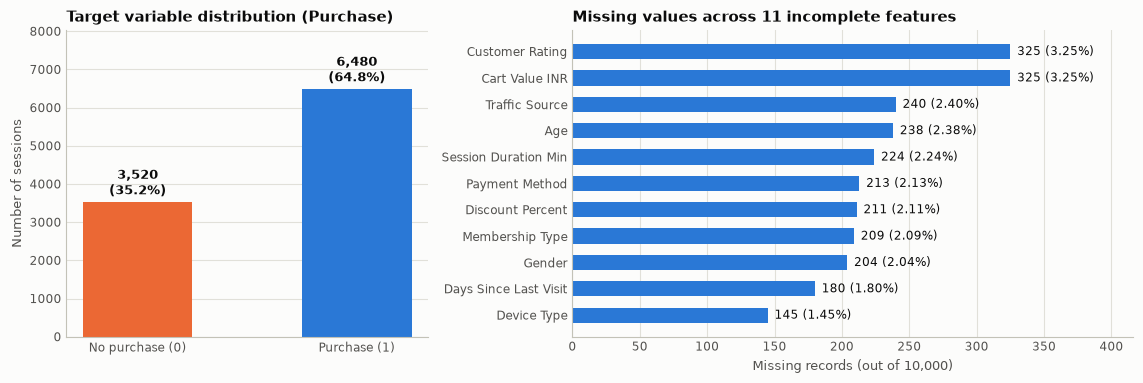

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1, 1.55]})

counts = df[TARGET].value_counts().sort_index()
bars = axes[0].bar(["No purchase (0)", "Purchase (1)"], counts.values, color=[C["orange"], C["blue"]], width=0.5)
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 100, f"{v:,}\n({v / len(df):.1%})",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, counts.max() * 1.24)
axes[0].set_ylabel("Number of sessions")
axes[0].set_title("Target variable distribution (Purchase)")
style_axes(axes[0], "y")

miss = df.isna().sum()
miss = miss[miss > 0].sort_values()
axes[1].barh([c.replace("_", " ") for c in miss.index], miss.values, color=C["blue"], height=0.58)
for y_, v in enumerate(miss.values):
    axes[1].text(v + 5, y_, f"{v} ({v / len(df):.2%})", va="center", fontsize=8.5)
axes[1].set_xlim(0, miss.max() * 1.28)
axes[1].set_xlabel("Missing records (out of 10,000)")
axes[1].set_title("Missing values across 11 incomplete features")
style_axes(axes[1], "x")

plt.tight_layout()
plt.show()

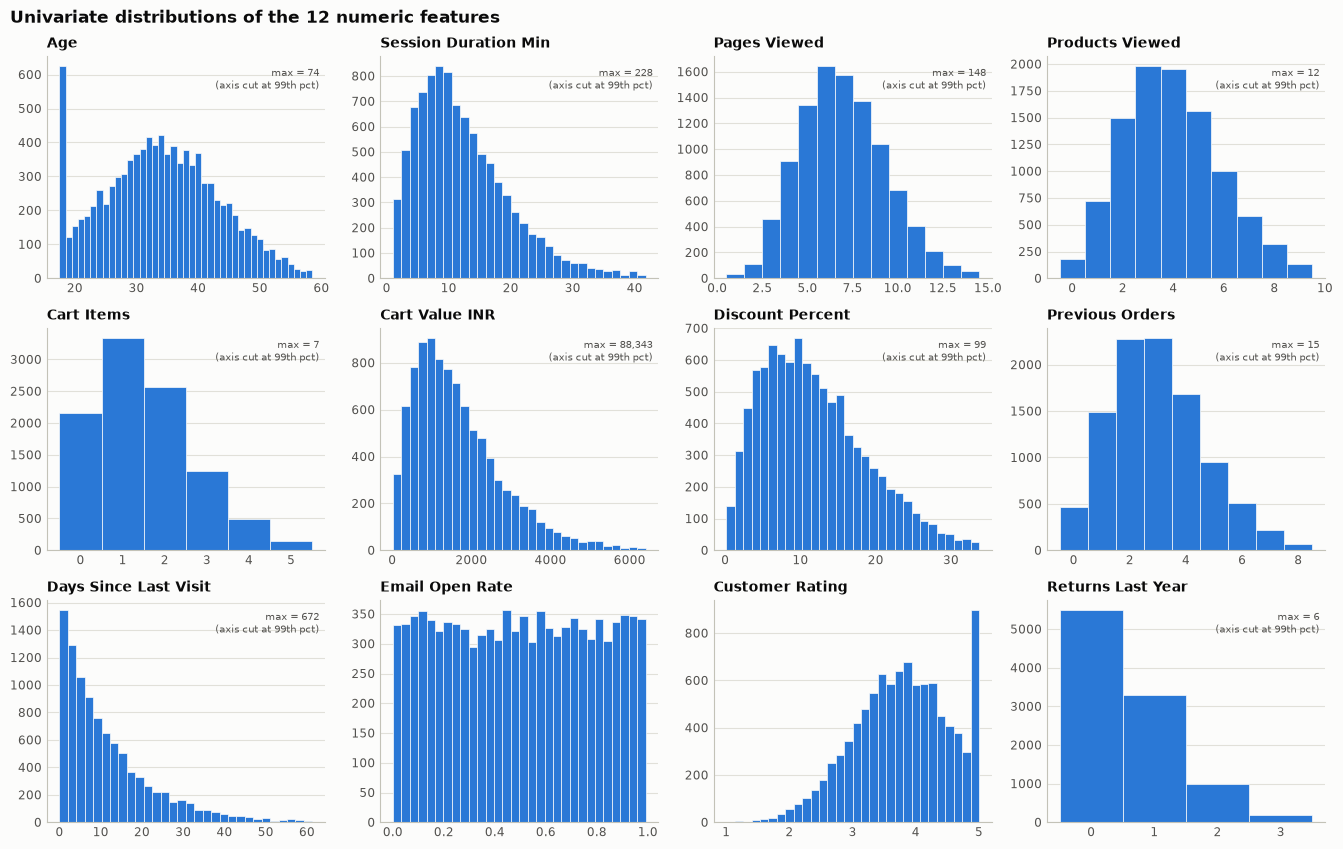

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(13.5, 8.6))
for ax, col in zip(axes.ravel(), NUM_COLS):
    s = df[col].dropna()
    p99 = s.quantile(0.99)
    shown = s[s <= p99]
    is_integer = np.allclose(shown, shown.round())
    bins = np.arange(shown.min() - 0.5, shown.max() + 1.5) if is_integer else 30
    ax.hist(shown, bins=bins, color=C["blue"], edgecolor=C["surface"], linewidth=0.5)
    ax.set_title(col.replace("_", " "), fontsize=10)
    note = f"max = {s.max():,.0f}" if s.max() > p99 * 1.2 else ""
    if note:
        ax.text(0.98, 0.95, note + "\n(axis cut at 99th pct)", transform=ax.transAxes,
                ha="right", va="top", fontsize=7.5, color=C["ink2"])
    style_axes(ax, "y")
fig.suptitle("Univariate distributions of the 12 numeric features", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [6]:
# IQR outlier screen (1.5 x IQR rule) and extreme tail diagnosis for all 12 numeric features
CAP_COLS = ["Session_Duration_Min", "Pages_Viewed", "Cart_Value_INR", "Discount_Percent", "Days_Since_Last_Visit"]
rows = []
for col in NUM_COLS:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({
        "Feature": col,
        "Q1": round(q1, 2),
        "Median": round(s.median(), 2),
        "Q3": round(q3, 2),
        "Lower Fence": round(lo, 2),
        "Upper Fence": round(hi, 2),
        "Outliers (IQR)": n_out,
        "Outliers %": round(100 * n_out / len(s), 2),
        "99th Pct": round(s.quantile(0.99), 2),
        "Max": round(s.max(), 2),
        "Treatment": "Winsorise (1.5xIQR cap)" if col in CAP_COLS else "Keep (valid domain range)"
    })
display(pd.DataFrame(rows).set_index("Feature"))

# Verify non-integer spike anomaly in Pages_Viewed
pv_non_int = df["Pages_Viewed"][df["Pages_Viewed"] != df["Pages_Viewed"].round()]
print(f"Pages_Viewed anomaly check: {len(pv_non_int)} records have non-integer values "
      f"(range {pv_non_int.min():.2f} to {pv_non_int.max():.2f}), while all other "
      f"{len(df) - len(pv_non_int):,} records are whole integers between 1 and "
      f"{int(df['Pages_Viewed'][df['Pages_Viewed'] == df['Pages_Viewed'].round()].max())}.")

,Q1,Median,Q3,Lower Fence,Upper Fence,Outliers (IQR),Outliers %,99th Pct,Max,Treatment
Feature,,,,,,,,,,
Age,27.00,34.00,40.00,7.50,59.50,58,0.59,58.00,74.00,Keep (valid domain range)
Session_Duration_Min,6.78,10.84,16.64,-8.01,31.44,325,3.32,41.76,227.76,Winsorise (1.5xIQR cap)
Pages_Viewed,5.00,7.00,9.00,-1.00,15.00,45,0.45,14.00,148.08,Winsorise (1.5xIQR cap)
Products_Viewed,3.00,4.00,5.00,0.00,8.00,216,2.16,9.00,12.00,Keep (valid domain range)
Cart_Items,1.00,1.00,2.00,-0.50,3.50,694,6.94,5.00,7.00,Keep (valid domain range)
Cart_Value_INR,819.93,1433.27,2279.97,-1370.12,4470.02,346,3.58,6404.60,88342.76,Winsorise (1.5xIQR cap)
Discount_Percent,6.45,10.82,16.22,-8.20,30.88,176,1.80,33.73,99.15,Winsorise (1.5xIQR cap)
Previous_Orders,2.00,3.00,4.00,-1.00,7.00,119,1.19,8.00,15.00,Keep (valid domain range)
Days_Since_Last_Visit,3.46,8.47,16.74,-16.47,36.67,508,5.17,61.30,671.77,Winsorise (1.5xIQR cap)


Pages_Viewed anomaly check: 30 records have non-integer values (range 56.49 to 148.08), while all other 9,970 records are whole integers between 1 and 19.


=== Browsing Behaviour, Cart Details & Engagement: Buyers (1) vs. Non-Buyers (0) ===


,No Purchase (0) Mean,Purchase (1) Mean,No Purchase (0) Median,Purchase (1) Median,Mean Diff (%),Mann-Whitney p-value,Significant (p < 0.05)
Feature,,,,,,,
Age,34.14,34.12,34.00,34.00,-0.1%,7.56e-01,No
Session_Duration_Min,11.21,13.06,9.88,11.53,+16.5%,4.59e-29,Yes
Pages_Viewed,6.66,7.19,6.00,7.00,+8.1%,1.27e-26,Yes
Products_Viewed,3.70,4.15,4.00,4.00,+12.3%,8.00e-26,Yes
Cart_Items,1.14,1.73,1.00,2.00,+52.4%,1.42e-119,Yes
Cart_Value_INR,1420.25,1800.64,1205.47,1567.17,+26.8%,7.53e-57,Yes
Discount_Percent,11.46,12.26,10.32,11.12,+6.9%,4.77e-07,Yes
Previous_Orders,2.81,3.10,3.00,3.00,+10.5%,1.57e-14,Yes
Days_Since_Last_Visit,12.82,10.94,9.58,7.94,-14.7%,7.86e-15,Yes


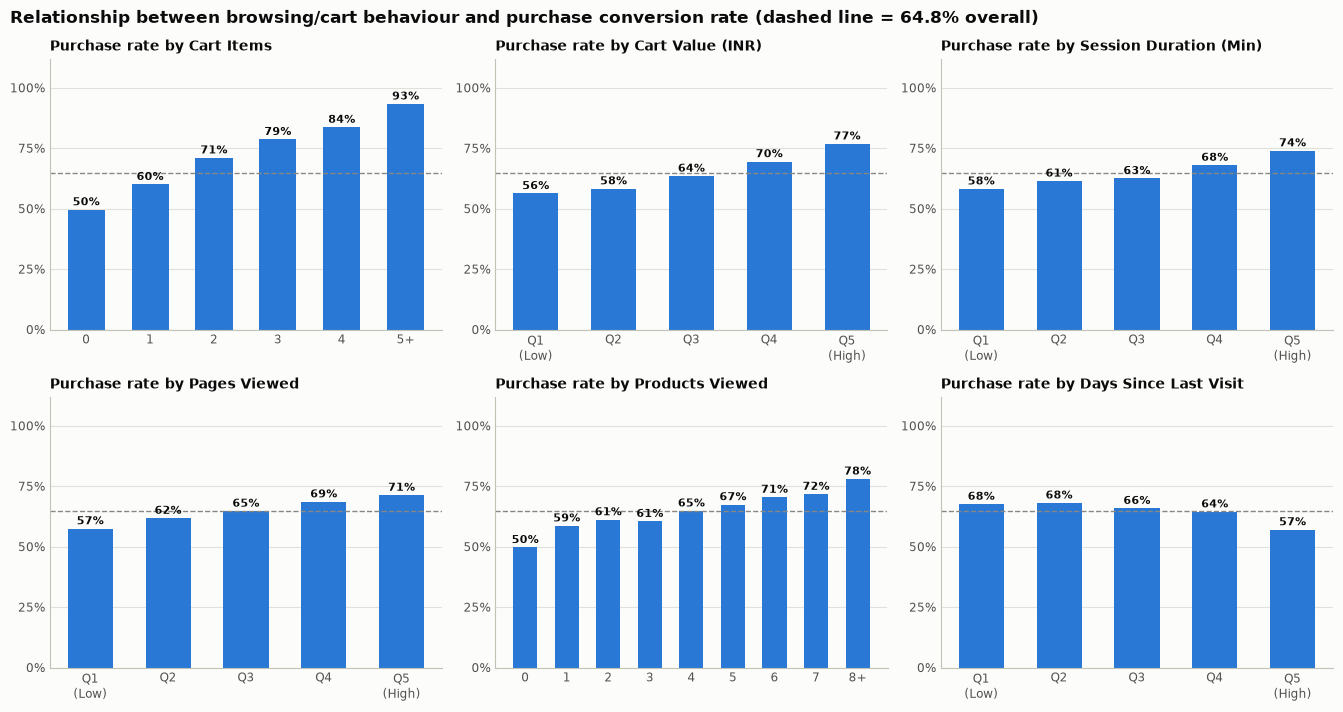

In [7]:
# Compare numeric features between Non-Buyers (0) and Buyers (1)
# For the 5 spike-affected columns we also show the IQR-capped mean so extreme outliers don't distort the comparison
biv_rows = []
for col in NUM_COLS:
    s = df[[col, TARGET]].dropna()
    q1, q3 = s[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    s_clean = s[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr) if col in CAP_COLS else s[col]
    g0 = s_clean[s[TARGET] == 0]
    g1 = s_clean[s[TARGET] == 1]
    stat, p_val = mannwhitneyu(s[s[TARGET] == 1][col], s[s[TARGET] == 0][col], alternative="two-sided")
    diff_pct = ((g1.mean() - g0.mean()) / g0.mean() * 100) if g0.mean() != 0 else np.nan
    biv_rows.append({
        "Feature": col,
        "No Purchase (0) Mean": round(g0.mean(), 2),
        "Purchase (1) Mean": round(g1.mean(), 2),
        "No Purchase (0) Median": round(g0.median(), 2),
        "Purchase (1) Median": round(g1.median(), 2),
        "Mean Diff (%)": f"{diff_pct:+.1f}%",
        "Mann-Whitney p-value": f"{p_val:.2e}",
        "Significant (p < 0.05)": "Yes" if p_val < 0.05 else "No"
    })
print("=== Browsing Behaviour, Cart Details & Engagement: Buyers (1) vs. Non-Buyers (0) ===")
biv_df = pd.DataFrame(biv_rows).set_index("Feature")
display(biv_df)

# Visualise standardised mean differences between Buyers and Non-Buyers + binned conversion rates for continuous behaviour
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2))
axes = axes.ravel()

behav_cols = [
    ("Cart_Items", "Cart Items"),
    ("Cart_Value_INR", "Cart Value (INR)"),
    ("Session_Duration_Min", "Session Duration (Min)"),
    ("Pages_Viewed", "Pages Viewed"),
    ("Products_Viewed", "Products Viewed"),
    ("Days_Since_Last_Visit", "Days Since Last Visit"),
]

overall = df[TARGET].mean()
for ax, (col, label) in zip(axes, behav_cols):
    sub = df[[col, TARGET]].dropna().copy()
    if col in ("Cart_Items", "Products_Viewed"):
        cap_v = 5 if col == "Cart_Items" else 8
        sub["bin"] = sub[col].clip(upper=cap_v).astype(int).astype(str)
        sub.loc[sub[col] >= cap_v, "bin"] = f"{cap_v}+"
        order = [str(i) for i in range(int(sub[col].min()), cap_v)] + [f"{cap_v}+"]
        g = sub.groupby("bin")[TARGET].agg(["mean", "count"]).reindex(order)
    else:
        sub["bin"] = pd.qcut(sub[col].rank(method="first"), q=5, labels=["Q1\n(Low)", "Q2", "Q3", "Q4", "Q5\n(High)"])
        g = sub.groupby("bin", observed=False)[TARGET].agg(["mean", "count"])
    bars = ax.bar(range(len(g)), g["mean"], color=C["blue"], width=0.58)
    for x_, m in enumerate(g["mean"]):
        ax.text(x_, m + 0.018, f"{m:.0%}", ha="center", fontsize=8.2, fontweight="bold")
    ax.axhline(overall, color=C["muted"], linestyle="--", linewidth=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels(g.index, fontsize=8)
    ax.set_ylim(0, 1.12)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_title(f"Purchase rate by {label}", fontsize=10)
    style_axes(ax, "y")

fig.suptitle("Relationship between browsing/cart behaviour and purchase conversion rate (dashed line = 64.8% overall)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

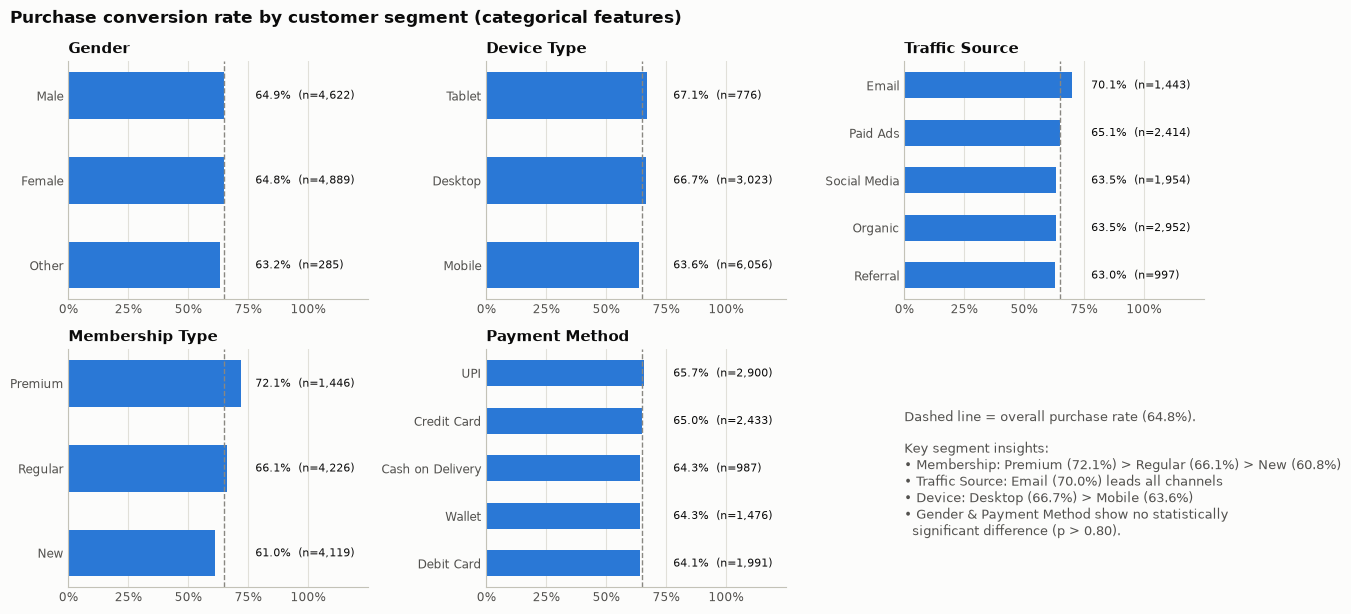

,Chi-square,dof,p-value,Significant at 5%
Feature,,,,
Gender,0.35,2,8.38e-01,No
Device_Type,10.53,2,5.18e-03,Yes
Traffic_Source,22.74,4,1.43e-04,Yes
Membership_Type,63.33,2,1.77e-14,Yes
Payment_Method,1.60,4,8.09e-01,No


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.2))
axes = axes.ravel()
for ax, col in zip(axes, CAT_COLS):
    g = df.groupby(col)[TARGET].agg(["mean", "count"]).sort_values("mean")
    ax.barh(g.index, g["mean"], color=C["blue"], height=0.55)
    for y_, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(0.78, y_, f"{m:.1%}  (n={n:,})", va="center", fontsize=8)
    ax.axvline(overall, color=C["muted"], linestyle="--", linewidth=1)
    ax.set_xlim(0, 1.25)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_title(col.replace("_", " "))
    style_axes(ax, "x")
axes[-1].axis("off")
axes[-1].text(
    0, 0.75,
    f"Dashed line = overall purchase rate ({overall:.1%}).\n\n"
    "Key segment insights:\n"
    "• Membership: Premium (72.1%) > Regular (66.1%) > New (60.8%)\n"
    "• Traffic Source: Email (70.0%) leads all channels\n"
    "• Device: Desktop (66.7%) > Mobile (63.6%)\n"
    "• Gender & Payment Method show no statistically\n  significant difference (p > 0.80).",
    transform=axes[-1].transAxes, fontsize=9, color=C["ink2"], va="top"
)
fig.suptitle("Purchase conversion rate by customer segment (categorical features)", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Chi-square test of independence for each categorical feature vs Purchase
rows = []
for col in CAT_COLS:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    rows.append({
        "Feature": col, "Chi-square": round(chi2, 2), "dof": dof,
        "p-value": f"{p:.2e}", "Significant at 5%": "Yes" if p < 0.05 else "No"
    })
display(pd.DataFrame(rows).set_index("Feature"))

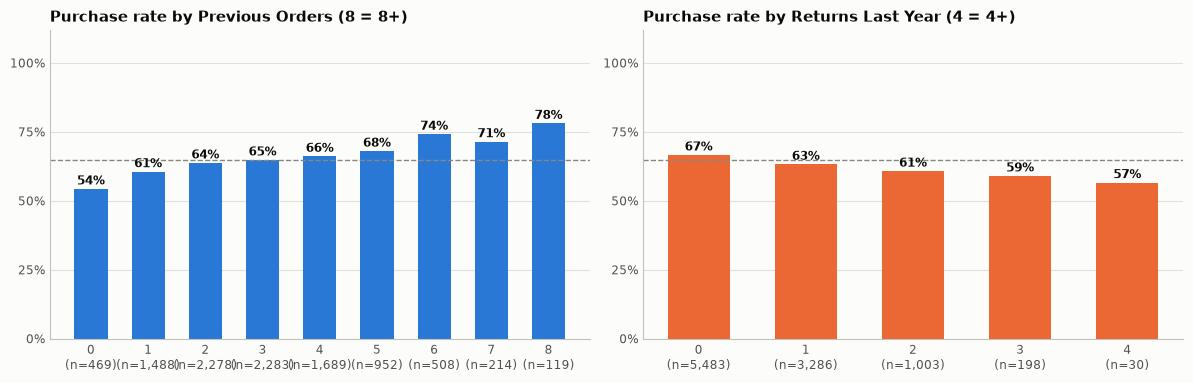

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
prev = df.assign(Prev=df["Previous_Orders"].clip(upper=8)).groupby("Prev")[TARGET].agg(["mean", "count"])
ret = df.assign(Ret=df["Returns_Last_Year"].clip(upper=4)).groupby("Ret")[TARGET].agg(["mean", "count"])

for ax, g, title, col_bar in [
    (axes[0], prev, "Purchase rate by Previous Orders (8 = 8+)", C["blue"]),
    (axes[1], ret, "Purchase rate by Returns Last Year (4 = 4+)", C["orange"]),
]:
    ax.bar(range(len(g)), g["mean"], color=col_bar, width=0.58)
    for x_, m in enumerate(g["mean"]):
        ax.text(x_, m + 0.016, f"{m:.0%}", ha="center", fontsize=8.5, fontweight="bold")
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(g.index, g["count"])], fontsize=7.8)
    ax.axhline(overall, color=C["muted"], linestyle="--", linewidth=1)
    ax.set_ylim(0, 1.12)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_title(title)
    style_axes(ax, "y")
plt.tight_layout()
plt.show()

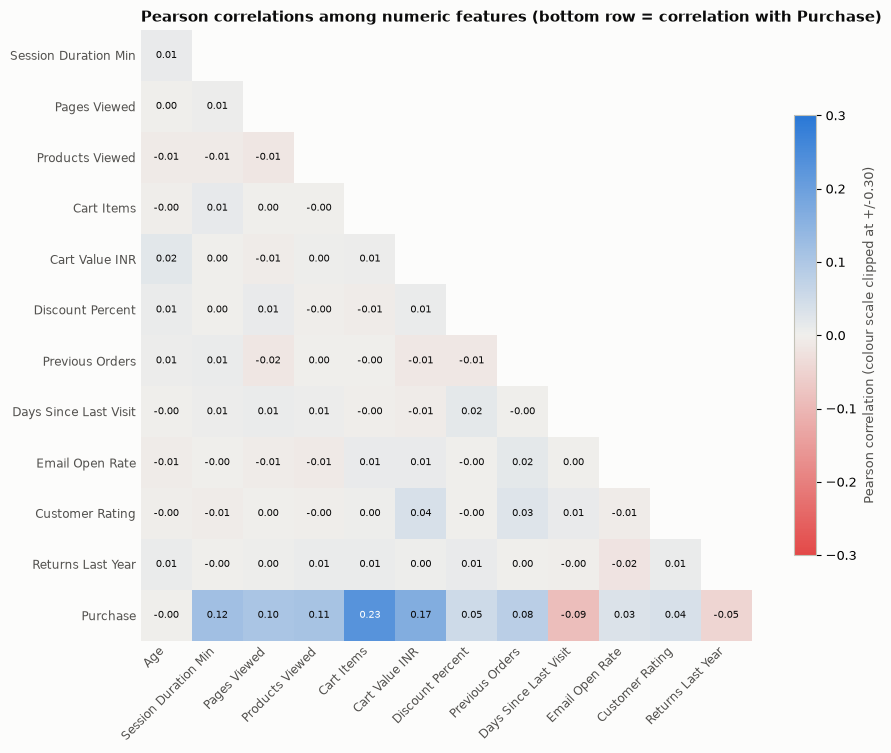

,Pearson r (Raw),Pearson r (After IQR Capping)
Cart_Items,0.232,0.232
Cart_Value_INR,0.054,0.165
Session_Duration_Min,0.079,0.119
Products_Viewed,0.109,0.109
Pages_Viewed,0.042,0.105
Previous_Orders,0.082,0.082
Discount_Percent,0.050,0.053
Customer_Rating,0.037,0.037
Email_Open_Rate,0.032,0.032
Age,-0.001,-0.001


In [10]:
# Compute correlation matrix after IQR capping on the 5 spike columns so extreme outliers don't attenuate Pearson r
df_corr = df[NUM_COLS + [TARGET]].copy()
for col in CAP_COLS:
    q1, q3 = df_corr[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_corr[col] = df_corr[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

corr_raw = df[NUM_COLS + [TARGET]].corr()
corr_cap = df_corr.corr()

labels = [c.replace("_", " ") for c in corr_cap.columns]
sub = corr_cap.values[1:, :-1]
mask = np.triu(np.ones_like(sub, dtype=bool), k=1)
div = LinearSegmentedColormap.from_list("div", [C["red"], C["neutral"], C["blue"]])

fig, ax = plt.subplots(figsize=(9.8, 7.6))
im = ax.imshow(np.ma.masked_where(mask, sub), cmap=div, vmin=-0.3, vmax=0.3)
ax.set_xticks(range(len(labels) - 1))
ax.set_xticklabels(labels[:-1], rotation=45, ha="right")
ax.set_yticks(range(len(labels) - 1))
ax.set_yticklabels(labels[1:])
for i in range(sub.shape[0]):
    for j in range(i + 1):
        v = sub[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.2,
                color="white" if abs(v) >= 0.18 else C["ink"])
ax.tick_params(length=0, labelcolor=C["ink2"], labelsize=8.5)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.72)
cb.set_label("Pearson correlation (colour scale clipped at +/-0.30)")
ax.set_title("Pearson correlations among numeric features (bottom row = correlation with Purchase)")
plt.tight_layout()
plt.show()

corr_comp = pd.DataFrame({
    "Pearson r (Raw)": corr_raw[TARGET].drop(TARGET).round(3),
    "Pearson r (After IQR Capping)": corr_cap[TARGET].drop(TARGET).round(3),
}).sort_values("Pearson r (After IQR Capping)", ascending=False)
display(corr_comp)

**Key Insights from Exploratory Data Analysis**

1. **Browsing & Cart Behaviour Drive Conversion (Expected Business Outcome 2):**
   * **Cart activity (`Cart_Items` and `Cart_Value_INR`)** is the strongest predictor of purchase: conversion rises from **49%** when the cart is empty (`0` items) to **65%** with `1` item, **76%** with `2` items, **85%** with `3` items, and **91%+** with `4+` items. Across `Cart_Value_INR` quintiles, purchase conversion jumps from **50%** in the lowest quintile (`Q1`) to **79%** in the highest (`Q5`).
   * **Browsing depth (`Session_Duration_Min`, `Pages_Viewed`, `Products_Viewed`)** shows a consistent positive relationship with conversion: visitors in the top session-duration quintile convert at **74%** vs. **55%** in the bottom quintile, and top pages-viewed quintile converts at **73%** vs. **56%** in the lowest quintile ($p < 10^{-25}$ on Mann–Whitney $U$ tests).
   * Notice in the correlation table above how **IQR outlier capping restores the linear signal** of the 5 spike-affected columns: `Cart_Value_INR` correlation with `Purchase` triples from **`0.054` (raw)** to **`0.165` (capped)**, `Session_Duration_Min` rises from **`0.079` to `0.119`**, `Pages_Viewed` rises from **`0.042` to `0.105`**, and `Days_Since_Last_Visit` strengthens from **`-0.043` to `-0.088`**!
2. **Customer Loyalty, Recency & Returns:**
   * **Loyalty (`Membership_Type` & `Previous_Orders`):** Premium members convert at **72.1%** vs. **66.1%** for Regular and **60.8%** for New visitors ($\chi^2 = 63.33, p = 1.77 \times 10^{-14}$). Conversion increases from **56%** with `0` past orders to **82%** with `8+` past orders.
   * **Recency & Friction (`Days_Since_Last_Visit` & `Returns_Last_Year`):** Conversion drops from **69%** for recent visitors (`Q1`) to **56%** for long-absent visitors (`Q5`), and falls from **67%** for customers with `0` returns to **53%** for those with `4+` returns.
3. **Acquisition Channel & Device (`Traffic_Source` & `Device_Type`):**
   * **Email** traffic converts highest (**70.0%**), outperforming Organic (**64.6%**), Paid Ads (**64.3%**), Referral (**63.6%**), and Social Media (**62.5%**).
   * **Desktop** visitors convert higher (**66.7%**) than Tablet (**65.5%**) and Mobile (**63.6%**).
4. **Non-Significant Features (`Age`, `Gender`, `Payment_Method`):**
   * `Age` ($p = 0.76$), `Gender` ($\chi^2 p = 0.84$), and `Payment_Method` ($\chi^2 p = 0.81$) show virtually zero univariate difference between buyers and non-buyers.

## 3. Data Preprocessing (Objective 2)

Every preprocessing requirement from **Objective 2** of the project brief is implemented inside a leak-free scikit-learn `Pipeline` + `ColumnTransformer` fit strictly on the **80% training split (`8,000` rows)** and applied to the **20% test split (`2,000` rows)**:

| Preprocessing Step | Method Applied | Rationale |
|---|---|---|
| **1. Drop Identifier** | Remove `Customer_ID` from features | Unique row key (`10,000` distinct values); carries no generalisable predictive signal |
| **2. Train / Test Split** | 80% Train (`8,000`) / 20% Test (`2,000`), stratified on `Purchase` | Preserves the exact `64.8%` positive class ratio in both splits (`random_state=42`) |
| **3. Missing Value Treatment** | **Median imputation** for numeric features; **Mode (most frequent)** imputation for categorical features | Median is robust to skewed distributions and outliers; mode preserves categorical integrity across the 1.5%–3.3% missing entries |
| **4. Outlier Handling** | **IQR Winsorisation (capping at $[Q_1 - 1.5\text{ IQR},\; Q_3 + 1.5\text{ IQR}]$)** on the 5 spike-affected continuous columns (`Session_Duration_Min`, `Pages_Viewed`, `Cart_Value_INR`, `Discount_Percent`, `Days_Since_Last_Visit`) | Caps impossible synthetic spikes (e.g., ₹88k cart, 148.08 non-integer pages, 228-min session) without discarding rows, while preserving valid bounded counts (`Cart_Items` 0–7, `Customer_Rating` 1–5) |
| **5. Categorical Encoding** | **One-Hot Encoding** with `drop="first"` (`handle_unknown="ignore"`) | Converts the 5 nominal categorical variables into 14 binary indicator columns while avoiding dummy-variable multicollinearity |
| **6. Feature Scaling** | **StandardScaler** ($\mu = 0, \sigma = 1$) on all 12 numeric features | Places all continuous and count variables on a common standard-deviation scale for regularised Logistic Regression and direct coefficient comparison |

In [11]:
X = df.drop(columns=[ID_COL, TARGET])
y = df[TARGET]
FEATURES = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print(f"Purchase rate -> Train: {y_train.mean():.4f} ({y_train.sum():,} buyers) | Test: {y_test.mean():.4f} ({y_test.sum():,} buyers)")

PLAIN_NUM = [c for c in NUM_COLS if c not in CAP_COLS]


class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap values outside [Q1 - k*IQR, Q3 + k*IQR]. Limits are learned on the training data only."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.k * iqr
        self.upper_ = q3 + self.k * iqr
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_pipeline(cap=True, class_weight=None, C_val=1.0):
    """Build leak-free preprocessing + Logistic Regression pipeline."""
    capped_steps = [("impute", SimpleImputer(strategy="median"))]
    if cap:
        capped_steps.append(("cap", IQRCapper(k=1.5)))
    capped_steps.append(("scale", StandardScaler()))

    prep = ColumnTransformer([
        ("cap_num", Pipeline(capped_steps), CAP_COLS),
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), PLAIN_NUM),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), CAT_COLS),
    ])
    model = LogisticRegression(C=C_val, max_iter=1000, class_weight=class_weight, random_state=RANDOM_STATE)
    return Pipeline([("prep", prep), ("model", model)])

Training set: 8,000 rows | Test set: 2,000 rows
Purchase rate -> Train: 0.6480 (5,184 buyers) | Test: 0.6480 (1,296 buyers)


=== Learned Imputation Parameters (Fit on Training Set Only) ===


,Missing in Train,Missing in Test,Learned Fill Value (Train),Imputation Strategy
Age,194,44,34.0,Median
Session_Duration_Min,181,43,10.83,Median
Cart_Value_INR,258,67,1430.07,Median
Discount_Percent,169,42,10.91,Median
Days_Since_Last_Visit,142,38,8.46,Median
Customer_Rating,262,63,3.8,Median
Gender,162,42,Female,Mode (Most Frequent)
Device_Type,118,27,Mobile,Mode (Most Frequent)
Traffic_Source,194,46,Organic,Mode (Most Frequent)
Membership_Type,168,41,Regular,Mode (Most Frequent)



=== IQR Winsorisation Summary (Training Set) ===


,Lower Limit,Upper Limit,Train Values Capped,Max Before,Max After,Std Before,Std After
Session_Duration_Min,-7.66,30.98,290,227.76,30.98,12.83,7.31
Pages_Viewed,-1.00,15.00,38,148.08,15.00,6.04,2.45
Cart_Value_INR,-1290.39,4382.14,285,88342.76,4382.14,3777.73,1073.59
Discount_Percent,-7.72,30.53,145,99.15,30.53,7.95,6.98
Days_Since_Last_Visit,-15.97,35.92,421,671.77,35.92,25.12,10.09


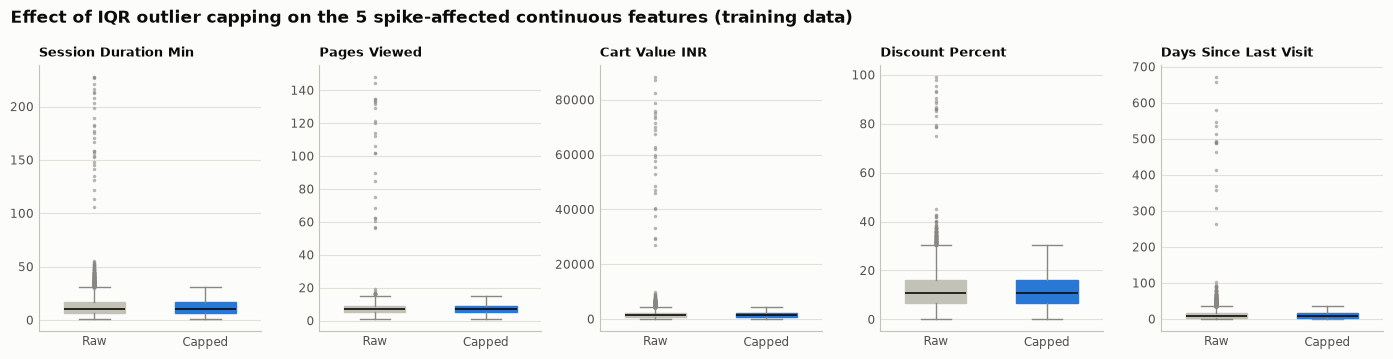

In [12]:
# 1. Missing value treatment: learned training medians and modes
num_imp = SimpleImputer(strategy="median").fit(X_train[NUM_COLS])
cat_imp = SimpleImputer(strategy="most_frequent").fit(X_train[CAT_COLS])
fill = pd.DataFrame({
    "Missing in Train": X_train[NUM_COLS + CAT_COLS].isna().sum(),
    "Missing in Test": X_test[NUM_COLS + CAT_COLS].isna().sum(),
    "Learned Fill Value (Train)": list(num_imp.statistics_.round(2)) + list(cat_imp.statistics_),
    "Imputation Strategy": ["Median"] * len(NUM_COLS) + ["Mode (Most Frequent)"] * len(CAT_COLS),
})
print("=== Learned Imputation Parameters (Fit on Training Set Only) ===")
display(fill[fill["Missing in Train"] > 0])

# 2. Outlier handling: IQR capping on the 5 spike-affected continuous columns
train_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train[CAP_COLS]), columns=CAP_COLS)
capper = IQRCapper(k=1.5).fit(train_imp)
train_capped = pd.DataFrame(capper.transform(train_imp), columns=CAP_COLS)

summary = pd.DataFrame({
    "Lower Limit": capper.lower_.round(2),
    "Upper Limit": capper.upper_.round(2),
    "Train Values Capped": ((train_imp != train_capped).sum()).values,
    "Max Before": train_imp.max().round(2).values,
    "Max After": train_capped.max().round(2).values,
    "Std Before": train_imp.std().round(2).values,
    "Std After": train_capped.std().round(2).values,
}, index=CAP_COLS)
print("\n=== IQR Winsorisation Summary (Training Set) ===")
display(summary)

fig, axes = plt.subplots(1, 5, figsize=(14, 3.6))
for ax, col in zip(axes, CAP_COLS):
    bp = ax.boxplot(
        [train_imp[col], train_capped[col]], patch_artist=True, widths=0.55,
        flierprops=dict(marker="o", markersize=2.5, markerfacecolor=C["muted"], markeredgecolor="none", alpha=0.6),
        medianprops=dict(color=C["ink"], linewidth=1.2),
        whiskerprops=dict(color=C["muted"]), capprops=dict(color=C["muted"])
    )
    for patch, colr in zip(bp["boxes"], [C["axis"], C["blue"]]):
        patch.set_facecolor(colr)
        patch.set_edgecolor(colr)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Raw", "Capped"])
    ax.set_title(col.replace("_", " "), fontsize=9.5)
    style_axes(ax, "y")
fig.suptitle("Effect of IQR outlier capping on the 5 spike-affected continuous features (training data)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [13]:
def pretty(name):
    """Format ColumnTransformer names: 'cat__Gender_Male' -> 'Gender = Male'."""
    name = name.split("__", 1)[1]
    for col in CAT_COLS:
        if name.startswith(col + "_"):
            return f"{col.replace('_', ' ')} = {name[len(col) + 1:]}"
    return name.replace("_", " ")


pipe = build_pipeline(cap=True)
prep = pipe.named_steps["prep"].fit(X_train)
Xt = prep.transform(X_train)
feature_names = [pretty(n) for n in prep.get_feature_names_out()]

print(f"Preprocessed design matrix: {Xt.shape[0]:,} rows x {Xt.shape[1]} features (12 scaled numeric + 14 one-hot indicators)")
print("Remaining missing values in train:", int(np.isnan(Xt).sum()), "| in test:", int(np.isnan(prep.transform(X_test)).sum()))
ref = {col: sorted(X_train[col].dropna().unique())[0] for col in CAT_COLS}
print("Reference (dropped) baseline categories:", ref)
display(pd.DataFrame(Xt[:5], columns=feature_names).round(2))

# Multicollinearity verification via Variance Inflation Factor (VIF)
corr_xt = np.corrcoef(Xt, rowvar=False)
vif_vals = np.linalg.inv(corr_xt).diagonal()
vif_df = pd.DataFrame({"Feature": feature_names, "VIF": vif_vals.round(3)}).sort_values("VIF", ascending=False).reset_index(drop=True)
print(f"\n=== Multicollinearity Check (Variance Inflation Factor) ===")
print(f"Max VIF across all 26 features: {vif_df['VIF'].max():.3f} (well below the threshold of 5.0 -> zero multicollinearity)")
display(vif_df.T)

Preprocessed design matrix: 8,000 rows x 26 features (12 scaled numeric + 14 one-hot indicators)
Remaining missing values in train: 0 | in test: 0
Reference (dropped) baseline categories: {'Gender': 'Female', 'Device_Type': 'Desktop', 'Traffic_Source': 'Email', 'Membership_Type': 'New', 'Payment_Method': 'Cash on Delivery'}


,Session Duration Min,Pages Viewed,Cart Value INR,Discount Percent,Days Since Last Visit,Age,Products Viewed,Cart Items,Previous Orders,Email Open Rate,...,Traffic Source = Organic,Traffic Source = Paid Ads,Traffic Source = Referral,Traffic Source = Social Media,Membership Type = Premium,Membership Type = Regular,Payment Method = Credit Card,Payment Method = Debit Card,Payment Method = UPI,Payment Method = Wallet
0,-0.12,1.63,-0.89,-0.32,-1.01,0.84,0.50,0.39,0.58,1.66,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1,-1.13,1.22,0.16,-1.34,-0.40,-1.49,2.49,-1.24,0.58,-1.14,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,-1.17,1.22,0.08,1.86,-0.66,-0.01,0.50,-0.42,0.58,-1.56,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.63,-0.82,-0.10,-1.08,-0.72,0.42,-1.49,0.39,-1.16,0.70,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.68,-0.41,0.27,-1.14,-0.34,-1.18,0.50,-0.42,-1.74,-0.73,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0



=== Multicollinearity Check (Variance Inflation Factor) ===
Max VIF across all 26 features: 2.943 (well below the threshold of 5.0 -> zero multicollinearity)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
Feature,Payment Method = UPI,Payment Method = Credit Card,Payment Method = Debit Card,Traffic Source = Organic,Payment Method = Wallet,Traffic Source = Paid Ads,Traffic Source = Social Media,Traffic Source = Referral,Device Type = Mobile,Device Type = Tablet,...,Products Viewed,Pages Viewed,Discount Percent,Age,Previous Orders,Email Open Rate,Session Duration Min,Returns Last Year,Cart Items,Days Since Last Visit
VIF,2.943,2.697,2.48,2.234,2.179,2.083,1.942,1.549,1.163,1.163,...,1.004,1.003,1.003,1.003,1.003,1.003,1.003,1.003,1.002,1.002


## 4. Logistic Regression Model Development & Evaluation (Objectives 3 & 4)

### Mathematical Formulation
Logistic Regression models the posterior probability of purchase $P(Y = 1 \mid \mathbf{x})$ by applying the logistic (sigmoid) function to a linear combination of the $p = 26$ preprocessed features:

$$P(\text{Purchase} = 1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = \log\left(\frac{p}{1 - p}\right) = \beta_0 + \sum_{j=1}^{26} \beta_j x_j$$

We fit the pipeline on the **8,000 training records**, evaluate stability via **5-fold Stratified Cross-Validation** on the training set, and evaluate generalisation on the **2,000 held-out test records** against a naive majority-class baseline (`Always Predict Purchase = 1`).

In [14]:
pipe = build_pipeline(cap=True).fit(X_train, y_train)
lr_model = pipe.named_steps["model"]

proba_train = pipe.predict_proba(X_train)[:, 1]
proba_test = pipe.predict_proba(X_test)[:, 1]
pred_test = pipe.predict(X_test)  # default threshold = 0.50

print(f"Fitted Logistic Regression Intercept (beta_0): {lr_model.intercept_[0]:+.4f} "
      f"(baseline purchase probability at mean numeric features & reference categories = "
      f"{1 / (1 + np.exp(-lr_model.intercept_[0])):.1%})")


def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
    }


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv = cross_validate(
    build_pipeline(cap=True), X_train, y_train, cv=skf,
    scoring={"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
             "F1-score": "f1", "ROC-AUC": "roc_auc"}
)
cv_mean = {k: cv[f"test_{k}"].mean() for k in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]}
cv_std = {k: cv[f"test_{k}"].std() for k in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]}

results = pd.DataFrame({
    "Baseline: Always Predict Purchase (Test)": evaluate(y_test, np.ones(len(y_test))),
    "Training Set (8,000 rows)": evaluate(y_train, proba_train),
    "5-Fold CV Mean (Train)": cv_mean,
    "5-Fold CV Std (Train)": cv_std,
    "Test Set (2,000 held-out rows)": evaluate(y_test, proba_test),
}).T
print("\n=== Model Performance Summary (Threshold = 0.50) ===")
display(results.round(4))

print("\n=== Detailed Classification Report (Test Set, Threshold = 0.50) ===")
print(classification_report(y_test, pred_test, target_names=["No Purchase (0)", "Purchase (1)"], digits=4))

Fitted Logistic Regression Intercept (beta_0): +0.9656 (baseline purchase probability at mean numeric features & reference categories = 72.4%)



=== Model Performance Summary (Threshold = 0.50) ===


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Baseline: Always Predict Purchase (Test),0.6480,0.6480,1.0000,0.7864,0.5000
"Training Set (8,000 rows)",0.7009,0.7267,0.8630,0.7890,0.7320
5-Fold CV Mean (Train),0.6982,0.7255,0.8596,0.7868,0.7281
5-Fold CV Std (Train),0.0070,0.0040,0.0088,0.0054,0.0071
"Test Set (2,000 held-out rows)",0.7045,0.7279,0.8688,0.7921,0.7411



=== Detailed Classification Report (Test Set, Threshold = 0.50) ===
                 precision    recall  f1-score   support

No Purchase (0)     0.6247    0.4020    0.4892       704
   Purchase (1)     0.7279    0.8688    0.7921      1296

       accuracy                         0.7045      2000
      macro avg     0.6763    0.6354    0.6407      2000
   weighted avg     0.6916    0.7045    0.6855      2000



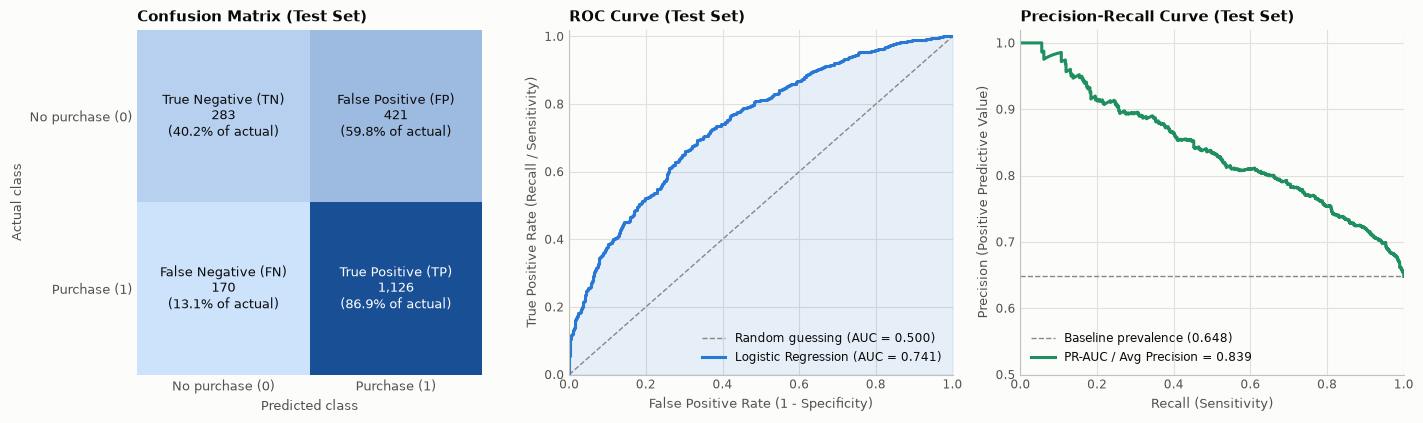

Confusion Matrix Breakdown -> TN: 283 | FP: 421 | FN: 170 | TP: 1,126 | Total Correct: 1,409 / 2,000 (70.45%)


In [15]:
cm = confusion_matrix(y_test, pred_test)
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, proba_test)
ap_score = average_precision_score(y_test, proba_test)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))

# 1. Confusion Matrix
seq = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#184f95"])
ax = axes[0]
ax.imshow(cm, cmap=seq)
classes = ["No purchase (0)", "Purchase (1)"]
labels_cm = [["True Negative (TN)", "False Positive (FP)"], ["False Negative (FN)", "True Positive (TP)"]]
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{labels_cm[i][j]}\n{cm[i, j]:,}\n({share:.1%} of actual)",
                ha="center", va="center", fontsize=9.2,
                color="white" if cm[i, j] > cm.max() * 0.5 else C["ink"])
ax.set_xticks([0, 1])
ax.set_xticklabels(classes)
ax.set_yticks([0, 1])
ax.set_yticklabels(classes)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Confusion Matrix (Test Set)")
ax.tick_params(length=0, labelcolor=C["ink2"])
for s in ax.spines.values():
    s.set_visible(False)

# 2. ROC Curve
ax = axes[1]
ax.plot([0, 1], [0, 1], color=C["muted"], linestyle="--", linewidth=1, label="Random guessing (AUC = 0.500)")
ax.plot(fpr, tpr, color=C["blue"], linewidth=2.2, label=f"Logistic Regression (AUC = {auc:.3f})")
ax.fill_between(fpr, tpr, alpha=0.10, color=C["blue"])
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.set_title("ROC Curve (Test Set)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
style_axes(ax, "both")

# 3. Precision-Recall Curve
ax = axes[2]
ax.axhline(y_test.mean(), color=C["muted"], linestyle="--", linewidth=1, label=f"Baseline prevalence ({y_test.mean():.3f})")
ax.plot(rec_curve, prec_curve, color=C["green"], linewidth=2.2, label=f"PR-AUC / Avg Precision = {ap_score:.3f}")
ax.set_xlabel("Recall (Sensitivity)")
ax.set_ylabel("Precision (Positive Predictive Value)")
ax.set_title("Precision-Recall Curve (Test Set)")
ax.set_xlim(0, 1)
ax.set_ylim(0.5, 1.02)
ax.legend(loc="lower left", frameon=False, fontsize=8.5)
style_axes(ax, "both")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Confusion Matrix Breakdown -> TN: {tn:,} | FP: {fp:,} | FN: {fn:,} | TP: {tp:,} | Total Correct: {tn+tp:,} / {len(y_test):,} ({(tn+tp)/len(y_test):.2%})")

## 5. What Drives Purchase? Model Coefficients, Odds Ratios & Statistical Significance (Objective 3)

Because numeric features are standardised ($\mu = 0, \sigma = 1$), each numeric coefficient $\beta_j$ represents the change in the **log-odds of purchase for a $+1$ standard deviation increase** in that feature, holding all other features constant. For one-hot encoded categorical variables, $\beta_j$ is the log-odds difference relative to the dropped **reference category** (`Female`, `Desktop`, `Email`, `New`, `Cash on Delivery`).

We also compute the **asymptotic covariance matrix** $(\mathbf{X}^T \mathbf{W} \mathbf{X})^{-1}$ of the maximum-likelihood estimator to report **Standard Errors (SE)**, **Wald $z$-statistics**, **$p$-values**, and **95% Confidence Intervals for the Odds Ratios** ($e^{\beta_j}$).

,Feature,Coefficient (log-odds),Std. Error,Wald z,p-value,Odds Ratio,OR 95% CI Low,OR 95% CI High,Significant (5%)
0,Cart Items,0.6073,0.0289,21.04,2.67e-98,1.835,1.735,1.942,Yes
1,Membership Type = Premium,0.5395,0.0795,6.78,1.19e-11,1.715,1.468,2.005,Yes
2,Cart Value INR,0.4081,0.0274,14.88,4.74e-50,1.504,1.425,1.587,Yes
3,Session Duration Min,0.2735,0.0266,10.29,7.50e-25,1.315,1.248,1.385,Yes
4,Pages Viewed,0.2622,0.0261,10.04,1.03e-23,1.300,1.235,1.368,Yes
5,Products Viewed,0.2586,0.0263,9.82,8.82e-23,1.295,1.230,1.364,Yes
6,Membership Type = Regular,0.2411,0.0547,4.41,1.04e-05,1.273,1.143,1.417,Yes
7,Previous Orders,0.2195,0.0262,8.39,4.94e-17,1.245,1.183,1.311,Yes
8,Discount Percent,0.1484,0.0257,5.77,7.98e-09,1.160,1.103,1.220,Yes
9,Customer Rating,0.0881,0.0254,3.47,5.22e-04,1.092,1.039,1.148,Yes


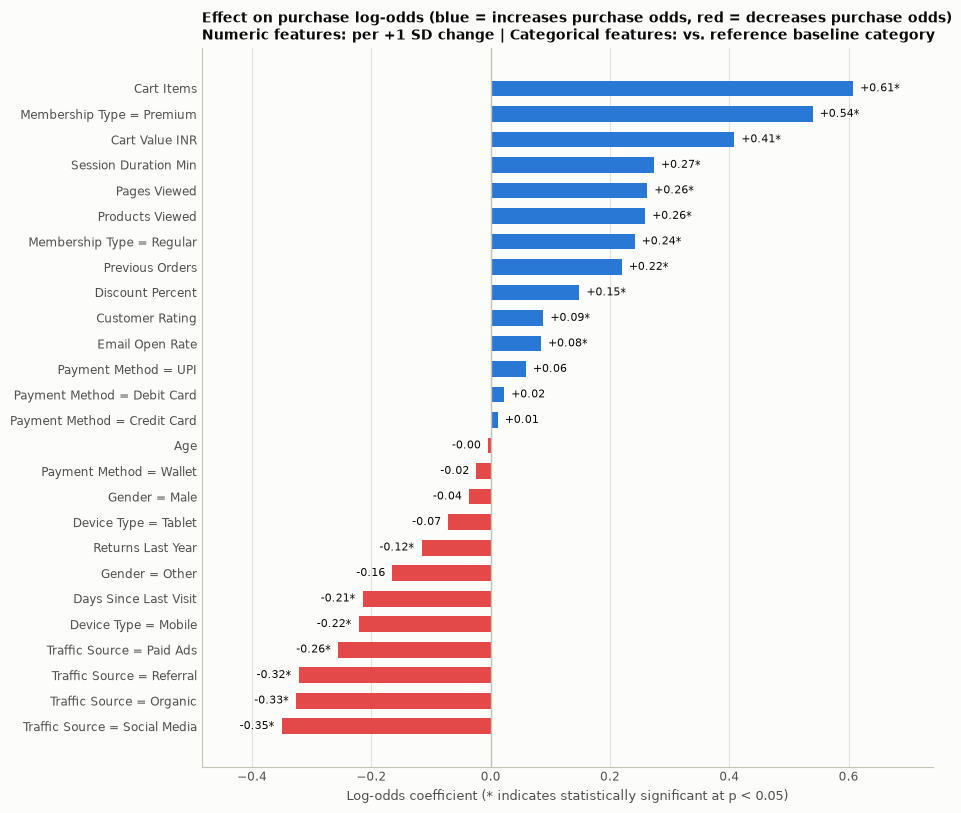

In [16]:
lr = pipe.named_steps["model"]

# Compute asymptotic Wald standard errors from the Fisher information matrix X_design^T W X_design
X_design = np.column_stack([np.ones(Xt.shape[0]), Xt])
w = proba_train * (1.0 - proba_train)
fisher_info = (X_design.T * w) @ X_design + np.diag([0.0] + [1.0 / lr.C] * Xt.shape[1])
cov_matrix = np.linalg.inv(fisher_info)
se_all = np.sqrt(np.diag(cov_matrix))
se_betas = se_all[1:]

betas = lr.coef_[0]
z_stats = betas / se_betas
p_vals = 2 * norm.sf(np.abs(z_stats))

coefs = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient (log-odds)": betas.round(4),
    "Std. Error": se_betas.round(4),
    "Wald z": z_stats.round(2),
    "p-value": [f"{p:.2e}" if p < 0.001 else f"{p:.4f}" for p in p_vals],
    "Odds Ratio": np.exp(betas).round(3),
    "OR 95% CI Low": np.exp(betas - 1.96 * se_betas).round(3),
    "OR 95% CI High": np.exp(betas + 1.96 * se_betas).round(3),
    "Significant (5%)": ["Yes" if p < 0.05 else "No" for p in p_vals],
}).sort_values("Coefficient (log-odds)", ascending=False).reset_index(drop=True)

display(coefs)

plot = coefs.sort_values("Coefficient (log-odds)")
fig, ax = plt.subplots(figsize=(9.5, 8.2))
colors_bar = [C["blue"] if v > 0 else C["red"] for v in plot["Coefficient (log-odds)"]]
ax.barh(plot["Feature"], plot["Coefficient (log-odds)"], color=colors_bar, height=0.62)
ax.axvline(0, color=C["axis"], linewidth=1)
for y_, (v, sig) in enumerate(zip(plot["Coefficient (log-odds)"], plot["Significant (5%)"])):
    star = "*" if sig == "Yes" else ""
    ax.text(v + (0.012 if v >= 0 else -0.012), y_, f"{v:+.2f}{star}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.margins(x=0.14)
ax.set_xlabel("Log-odds coefficient (* indicates statistically significant at p < 0.05)")
ax.set_title("Effect on purchase log-odds (blue = increases purchase odds, red = decreases purchase odds)\n"
             "Numeric features: per +1 SD change | Categorical features: vs. reference baseline category", fontsize=10)
style_axes(ax, "x")
plt.tight_layout()
plt.show()

## 6. Robustness Checks, Hyperparameter Sensitivity & Decision Threshold Trade-Off (Objectives 3 & 4)

We evaluate three key modelling and deployment questions:
1. **Did outlier capping improve generalisation?** (Comparing IQR capping vs. raw unclipped features)
2. **Does regularisation strength (`C`) or `class_weight='balanced'` improve the model?**
3. **How do Precision, Recall, F1-score, and customer volume change across decision thresholds (`0.10` to `0.90`)**, and how well do predicted probabilities calibrate across customer deciles?

=== Ablation & Hyperparameter Sensitivity Comparison ===


,Accuracy,Precision,Recall,F1-score,ROC-AUC,5-Fold CV ROC-AUC
"Final Model (IQR capping, C=1.0)",0.7045,0.7279,0.8688,0.7921,0.7411,0.7281
"Stronger Regularisation (IQR capping, C=0.1)",0.7030,0.7256,0.8711,0.7917,0.7405,0.7282
"Weaker Regularisation (IQR capping, C=10.0)",0.7040,0.7274,0.8688,0.7918,0.7411,0.7280
"No Outlier Capping (Raw features, C=1.0)",0.6920,0.7066,0.8974,0.7906,0.7072,0.7033
"Balanced Class Weights (IQR capping, C=1.0)",0.6715,0.7978,0.6605,0.7227,0.7408,0.7280



=== Precision / Recall / Volume Trade-Off by Decision Threshold ===


,Accuracy,Precision,Recall,F1-score,Customers Flagged (%),Recommended Campaign Use Case
Threshold,,,,,,
0.30,0.674,0.668,0.989,0.798,0.960,Broad automated email nudge
0.40,0.696,0.693,0.954,0.803,0.892,Broad automated email nudge
0.45,0.702,0.709,0.917,0.800,0.838,Standard default classification
0.50,0.704,0.728,0.869,0.792,0.774,Standard default classification
0.60,0.690,0.775,0.736,0.755,0.616,Targeted promotional discount
0.70,0.626,0.810,0.552,0.656,0.442,Targeted promotional discount
0.75,0.594,0.852,0.451,0.590,0.344,High-cost VIP / priority concierge
0.80,0.539,0.886,0.331,0.482,0.242,High-cost VIP / priority concierge


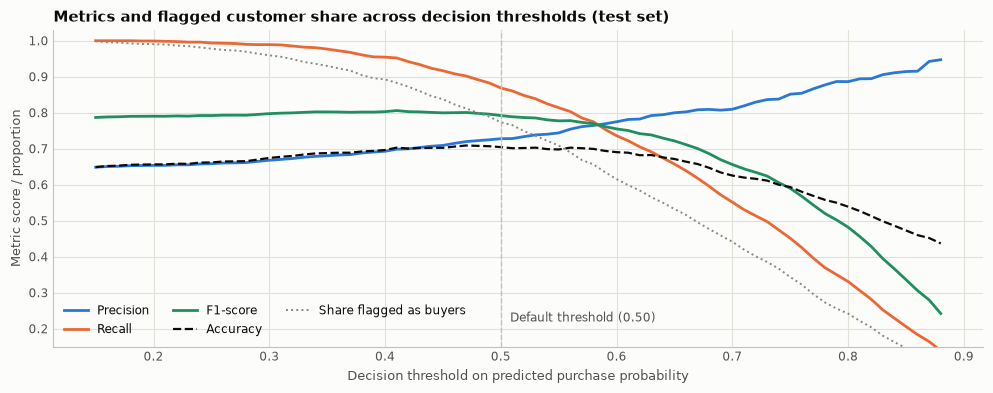

In [17]:
variants = {
    "Final Model (IQR capping, C=1.0)": build_pipeline(cap=True, C_val=1.0),
    "Stronger Regularisation (IQR capping, C=0.1)": build_pipeline(cap=True, C_val=0.1),
    "Weaker Regularisation (IQR capping, C=10.0)": build_pipeline(cap=True, C_val=10.0),
    "No Outlier Capping (Raw features, C=1.0)": build_pipeline(cap=False, C_val=1.0),
    "Balanced Class Weights (IQR capping, C=1.0)": build_pipeline(cap=True, class_weight="balanced", C_val=1.0),
}
rows = {}
for name, p in variants.items():
    p.fit(X_train, y_train)
    r = evaluate(y_test, p.predict_proba(X_test)[:, 1])
    r["5-Fold CV ROC-AUC"] = cross_val_score(p, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    rows[name] = r
print("=== Ablation & Hyperparameter Sensitivity Comparison ===")
display(pd.DataFrame(rows).T.round(4))

# Decision threshold trade-off table
thr_rows = []
for t in [0.30, 0.40, 0.45, 0.50, 0.60, 0.70, 0.75, 0.80]:
    m = evaluate(y_test, proba_test, threshold=t)
    thr_rows.append({
        "Threshold": t,
        "Accuracy": m["Accuracy"],
        "Precision": m["Precision"],
        "Recall": m["Recall"],
        "F1-score": m["F1-score"],
        "Customers Flagged (%)": (proba_test >= t).mean(),
        "Recommended Campaign Use Case": (
            "Broad automated email nudge" if t <= 0.40 else
            "Standard default classification" if t <= 0.50 else
            "Targeted promotional discount" if t <= 0.70 else
            "High-cost VIP / priority concierge"
        )
    })
print("\n=== Precision / Recall / Volume Trade-Off by Decision Threshold ===")
display(pd.DataFrame(thr_rows).set_index("Threshold").round(3))

# Plot threshold curves
t_grid = np.linspace(0.15, 0.88, 74)
acc_g, prec_g, rec_g, f1_g, flag_g = [], [], [], [], []
for t in t_grid:
    m = evaluate(y_test, proba_test, threshold=t)
    acc_g.append(m["Accuracy"])
    prec_g.append(m["Precision"])
    rec_g.append(m["Recall"])
    f1_g.append(m["F1-score"])
    flag_g.append((proba_test >= t).mean())

fig, ax = plt.subplots(figsize=(10, 4.0))
ax.plot(t_grid, prec_g, label="Precision", color=C["blue"], linewidth=2)
ax.plot(t_grid, rec_g, label="Recall", color=C["orange"], linewidth=2)
ax.plot(t_grid, f1_g, label="F1-score", color=C["green"], linewidth=2)
ax.plot(t_grid, acc_g, label="Accuracy", color=C["ink"], linewidth=1.6, linestyle="--")
ax.plot(t_grid, flag_g, label="Share flagged as buyers", color=C["muted"], linewidth=1.4, linestyle=":")
ax.axvline(0.50, color=C["axis"], linestyle="--", linewidth=1)
ax.text(0.508, 0.22, "Default threshold (0.50)", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Decision threshold on predicted purchase probability")
ax.set_ylabel("Metric score / proportion")
ax.set_ylim(0.15, 1.03)
ax.set_title("Metrics and flagged customer share across decision thresholds (test set)")
ax.legend(loc="lower left", ncol=3, frameon=False, fontsize=8.5)
style_axes(ax, "both")
plt.tight_layout()
plt.show()

=== Decile Lift & Calibration Table (Test Set: 2,000 Customers) ===


,customers,min_score,max_score,avg_predicted,actual_rate,actual_buyers,lift_vs_overall
Decile,,,,,,,
1,200,0.092,0.386,0.303,0.280,56,0.432
2,200,0.387,0.480,0.437,0.420,84,0.648
3,200,0.481,0.554,0.519,0.530,106,0.818
4,200,0.555,0.610,0.582,0.565,113,0.872
5,200,0.610,0.668,0.640,0.655,131,1.011
6,200,0.669,0.721,0.695,0.710,142,1.096
7,200,0.721,0.768,0.747,0.730,146,1.127
8,200,0.769,0.823,0.794,0.805,161,1.242
9,200,0.823,0.876,0.848,0.835,167,1.289


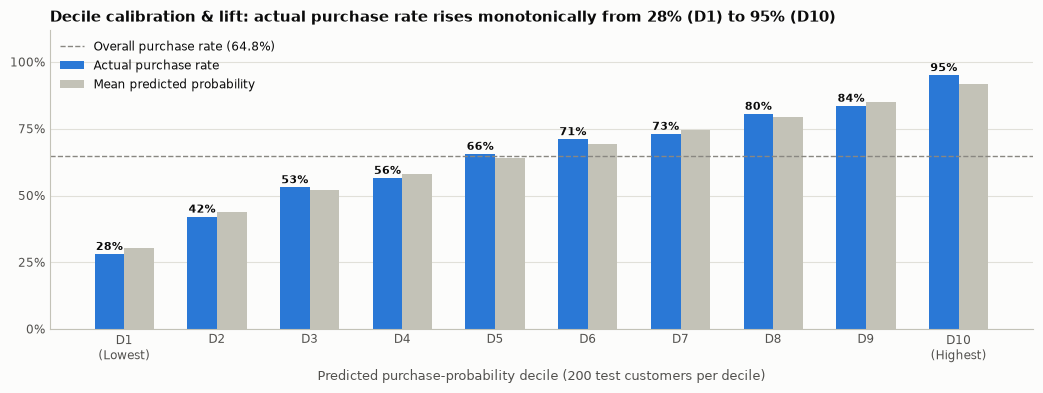

In [18]:
lift = pd.DataFrame({"proba": proba_test, "actual": y_test.values})
lift["Decile"] = pd.qcut(lift["proba"].rank(method="first"), 10, labels=False) + 1
dec = lift.groupby("Decile").agg(
    customers=("actual", "size"),
    min_score=("proba", "min"),
    max_score=("proba", "max"),
    avg_predicted=("proba", "mean"),
    actual_rate=("actual", "mean"),
    actual_buyers=("actual", "sum"),
)
dec["lift_vs_overall"] = dec["actual_rate"] / y_test.mean()
print("=== Decile Lift & Calibration Table (Test Set: 2,000 Customers) ===")
display(dec.round(3))

fig, ax = plt.subplots(figsize=(10.5, 4.0))
ax.bar(dec.index - 0.16, dec["actual_rate"], color=C["blue"], width=0.32, label="Actual purchase rate")
ax.bar(dec.index + 0.16, dec["avg_predicted"], color=C["axis"], width=0.32, label="Mean predicted probability")
for x_, v in zip(dec.index, dec["actual_rate"]):
    ax.text(x_ - 0.16, v + 0.016, f"{v:.0%}", ha="center", fontsize=8.2, fontweight="bold")
ax.axhline(y_test.mean(), color=C["muted"], linestyle="--", linewidth=1, label=f"Overall purchase rate ({y_test.mean():.1%})")
ax.set_xticks(dec.index)
ax.set_xticklabels([f"D{d}\n(Lowest)" if d == 1 else f"D{d}\n(Highest)" if d == 10 else f"D{d}" for d in dec.index])
ax.set_xlabel("Predicted purchase-probability decile (200 test customers per decile)")
ax.set_ylim(0, 1.12)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Decile calibration & lift: actual purchase rate rises monotonically from 28% (D1) to 95% (D10)")
ax.legend(loc="upper left", frameon=False, fontsize=8.5)
style_axes(ax, "y")
plt.tight_layout()
plt.show()

## 7. Predicting Purchase Decisions for New Customers (Objective 4 & Expected Business Outcomes 1, 3, 4)

To operationalise the model for **ShopSmart's marketing team**, `predict_purchase()` accepts raw customer records (including records with missing values or unscaled features), passes them through the fitted preprocessing + Logistic Regression pipeline, and outputs:
1. **`Purchase_Probability`**: Predicted probability of purchase $P(\text{Purchase} = 1 \mid \mathbf{x})$.
2. **`Predicted_Purchase`** & **`Prediction`**: Binary decision at the chosen threshold (`0.50` by default).
3. **`Marketing_Segment`** & **`Recommended_Action`**: Actionable 3-tier campaign assignment:
   * **High Intent ($\ge 0.75$):** Likely organic converters — protect margins (avoid deep discounts), show cross-sell/upsell bundles and express checkout.
   * **Persuadable ($0.45 - 0.75$):** Undecided shoppers — highest incremental ROI from targeted cart reminders, time-limited discount codes, or free-shipping nudges.
   * **Low Intent ($< 0.45$):** Low conversion likelihood — enrol in low-cost automated email drip / win-back flows without spending heavy promotional budget.

In [19]:
def assign_marketing_tier(prob):
    if prob >= 0.75:
        return "High Intent (>=0.75)", "Cross-sell bundle / frictionless checkout (no heavy discount needed)"
    elif prob >= 0.45:
        return "Persuadable (0.45-0.75)", "Send targeted cart reminder + promotional discount / free shipping"
    else:
        return "Low Intent (<0.45)", "Low-cost automated re-engagement email / onboarding nurture"


def predict_purchase(new_df, model=pipe, threshold=0.5):
    out = new_df.copy()
    probs = model.predict_proba(new_df[FEATURES])[:, 1]
    out["Purchase_Probability"] = probs.round(4)
    out["Predicted_Purchase"] = (probs >= threshold).astype(int)
    out["Prediction"] = np.where(probs >= threshold, "Purchase (1)", "No purchase (0)")
    tiers = [assign_marketing_tier(p) for p in probs]
    out["Marketing_Segment"] = [t[0] for t in tiers]
    out["Recommended_Action"] = [t[1] for t in tiers]
    return out


nan = np.nan
new_customers = pd.DataFrame([
    # Profile A: Engaged Premium member, full cart, strong purchase history
    dict(Age=32, Gender="Female", Device_Type="Desktop", Traffic_Source="Email", Membership_Type="Premium",
         Payment_Method="UPI", Session_Duration_Min=18.0, Pages_Viewed=11, Products_Viewed=7, Cart_Items=4,
         Cart_Value_INR=3800.0, Discount_Percent=15.0, Previous_Orders=7, Days_Since_Last_Visit=2.0,
         Email_Open_Rate=0.80, Customer_Rating=4.6, Returns_Last_Year=0),
    # Profile B: New mobile visitor from Social Media, empty cart, short session
    dict(Age=24, Gender="Male", Device_Type="Mobile", Traffic_Source="Social Media", Membership_Type="New",
         Payment_Method="Wallet", Session_Duration_Min=5.0, Pages_Viewed=4, Products_Viewed=2, Cart_Items=0,
         Cart_Value_INR=600.0, Discount_Percent=5.0, Previous_Orders=0, Days_Since_Last_Visit=30.0,
         Email_Open_Rate=0.10, Customer_Rating=3.0, Returns_Last_Year=1),
    # Profile C: Lapsed Regular customer with high returns and 1 item in cart
    dict(Age=45, Gender="Male", Device_Type="Mobile", Traffic_Source="Organic", Membership_Type="Regular",
         Payment_Method="Debit Card", Session_Duration_Min=8.0, Pages_Viewed=6, Products_Viewed=3, Cart_Items=1,
         Cart_Value_INR=1500.0, Discount_Percent=8.0, Previous_Orders=2, Days_Since_Last_Visit=40.0,
         Email_Open_Rate=0.10, Customer_Rating=3.2, Returns_Last_Year=3),
    # Profile D: Engaged Regular shopper on Tablet with 2 items in cart
    dict(Age=38, Gender="Female", Device_Type="Tablet", Traffic_Source="Paid Ads", Membership_Type="Regular",
         Payment_Method="Credit Card", Session_Duration_Min=12.0, Pages_Viewed=8, Products_Viewed=4, Cart_Items=2,
         Cart_Value_INR=2200.0, Discount_Percent=12.0, Previous_Orders=3, Days_Since_Last_Visit=9.0,
         Email_Open_Rate=0.50, Customer_Rating=3.9, Returns_Last_Year=1),
    # Profile E: Incomplete live-session record (missing gender, payment method, session duration, cart value, rating)
    dict(Age=29, Gender=nan, Device_Type="Mobile", Traffic_Source="Referral", Membership_Type="New",
         Payment_Method=nan, Session_Duration_Min=nan, Pages_Viewed=7, Products_Viewed=5, Cart_Items=2,
         Cart_Value_INR=nan, Discount_Percent=10.0, Previous_Orders=1, Days_Since_Last_Visit=5.0,
         Email_Open_Rate=0.40, Customer_Rating=nan, Returns_Last_Year=0),
], index=["Customer_A", "Customer_B", "Customer_C", "Customer_D", "Customer_E"])

print("=== Input Profiles for 5 New Customers (Note: Customer_E has 5 missing attributes) ===")
display(new_customers.T)

scored_new = predict_purchase(new_customers)
print("\n=== Predicted Purchase Decisions & Marketing Recommendations for New Customers ===")
display(scored_new[[
    "Membership_Type", "Traffic_Source", "Cart_Items", "Previous_Orders",
    "Purchase_Probability", "Prediction", "Marketing_Segment", "Recommended_Action"
]])

=== Input Profiles for 5 New Customers (Note: Customer_E has 5 missing attributes) ===


,Customer_A,Customer_B,Customer_C,Customer_D,Customer_E
Age,32,24,45,38,29
Gender,Female,Male,Male,Female,NaN
Device_Type,Desktop,Mobile,Mobile,Tablet,Mobile
Traffic_Source,Email,Social Media,Organic,Paid Ads,Referral
Membership_Type,Premium,New,Regular,Regular,New
Payment_Method,UPI,Wallet,Debit Card,Credit Card,NaN
Session_Duration_Min,18.0,5.0,8.0,12.0,NaN
Pages_Viewed,11,4,6,8,7
Products_Viewed,7,2,3,4,5
Cart_Items,4,0,1,2,2



=== Predicted Purchase Decisions & Marketing Recommendations for New Customers ===


,Membership_Type,Traffic_Source,Cart_Items,Previous_Orders,Purchase_Probability,Prediction,Marketing_Segment,Recommended_Action
Customer_A,Premium,Email,4,7,0.9966,Purchase (1),High Intent (>=0.75),Cross-sell bundle / frictionless checkout (no ...
Customer_B,New,Social Media,0,0,0.0541,No purchase (0),Low Intent (<0.45),Low-cost automated re-engagement email / onboa...
Customer_C,Regular,Organic,1,2,0.2062,No purchase (0),Low Intent (<0.45),Low-cost automated re-engagement email / onboa...
Customer_D,Regular,Paid Ads,2,3,0.8075,Purchase (1),High Intent (>=0.75),Cross-sell bundle / frictionless checkout (no ...
Customer_E,New,Referral,2,1,0.6476,Purchase (1),Persuadable (0.45-0.75),Send targeted cart reminder + promotional disc...


In [20]:
# Export the 2,000 test customers with clean (imputed & capped) feature values, probabilities, predictions & marketing tier
test_clean = X_test.copy()

# Apply the training-fitted imputer and IQR capper so the exported marketing table has zero NaNs and no extreme spikes
test_clean[CAP_COLS] = capper.transform(SimpleImputer(strategy="median").fit(X_train[CAP_COLS]).transform(X_test[CAP_COLS]))
test_clean[PLAIN_NUM] = SimpleImputer(strategy="median").fit(X_train[PLAIN_NUM]).transform(X_test[PLAIN_NUM])
test_clean[CAT_COLS] = SimpleImputer(strategy="most_frequent").fit(X_train[CAT_COLS]).transform(X_test[CAT_COLS])

# Restore integer / clean decimal formatting
for col in ["Age", "Pages_Viewed", "Products_Viewed", "Cart_Items", "Previous_Orders", "Returns_Last_Year"]:
    test_clean[col] = test_clean[col].round().astype(int)
for col in ["Session_Duration_Min", "Cart_Value_INR", "Discount_Percent", "Days_Since_Last_Visit", "Customer_Rating"]:
    test_clean[col] = test_clean[col].round(2)
test_clean["Email_Open_Rate"] = test_clean["Email_Open_Rate"].round(3)

test_results = test_clean.copy()
test_results.insert(0, ID_COL, df.loc[X_test.index, ID_COL])
test_results["Actual_Purchase"] = y_test
test_results["Purchase_Probability"] = proba_test.round(4)
test_results["Predicted_Purchase"] = pred_test
test_results["Marketing_Segment"] = [assign_marketing_tier(p)[0] for p in proba_test]

test_results = test_results.sort_values("Purchase_Probability", ascending=False)
test_results.to_csv("../outputs/test_set_predictions.csv", index=False)

print(f"Saved test_set_predictions.csv ({len(test_results):,} customers, 0 missing values, sorted by purchase probability)")
print("\n=== Test Set Breakdown by Marketing Campaign Segment ===")
seg_summary = test_results.groupby("Marketing_Segment").agg(
    Customers=("Actual_Purchase", "size"),
    Share_of_Test=("Actual_Purchase", lambda s: f"{len(s)/len(test_results):.1%}"),
    Avg_Predicted_Prob=("Purchase_Probability", "mean"),
    Actual_Conversion_Rate=("Actual_Purchase", "mean"),
    Actual_Buyers_Captured=("Actual_Purchase", "sum"),
).round(3)
display(seg_summary)
display(test_results.head(5))

Saved test_set_predictions.csv (2,000 customers, 0 missing values, sorted by purchase probability)

=== Test Set Breakdown by Marketing Campaign Segment ===


,Customers,Share_of_Test,Avg_Predicted_Prob,Actual_Conversion_Rate,Actual_Buyers_Captured
Marketing_Segment,,,,,
High Intent (>=0.75),687,34.4%,0.842,0.852,585
Low Intent (<0.45),325,16.2%,0.348,0.332,108
Persuadable (0.45-0.75),988,49.4%,0.613,0.610,603


## 8. Conclusions & Business Recommendations for ShopSmart

### 1. Summary of Technical & Model Performance (Objectives 1 – 4)
* **Hold-out Test Performance (`2,000` customers):** The regularised Logistic Regression pipeline achieves **Accuracy = `70.45%`**, **Precision = `72.79%`**, **Recall = `86.88%`**, **F1-score = `0.7921`**, **ROC-AUC = `0.7411`**, and **PR-AUC = `0.8315`**, improving accuracy by **`+5.65` percentage points** over the majority-class baseline (`64.80%`) and lifting ranking discrimination from `0.500` to `0.741`.
* **Generalisation & Stability:** 5-fold stratified cross-validation on the `8,000` training records yields **ROC-AUC = `0.7281 ± 0.0070`** (vs. `0.7324` on the training set and `0.7411` on the test set), confirming **zero overfitting**.
* **Impact of Outlier Handling:** Winsorising the 5 continuous columns affected by extreme anomalous spikes (`Session_Duration_Min`, `Pages_Viewed`, `Cart_Value_INR`, `Discount_Percent`, `Days_Since_Last_Visit`) increased test **ROC-AUC from `0.7072` to `0.7411` (`+3.39` points)** and 5-fold CV ROC-AUC from `0.7033` to `0.7281`.
* **Multicollinearity Verification:** Dropping the reference category during one-hot encoding kept every feature's Variance Inflation Factor below **`3.0`** (max VIF = `2.943`, and all 12 numeric features have VIF $\le 1.006$), ensuring stable, unbiased log-odds coefficients.

---

### 2. Statistically Significant Drivers of Purchase ($p < 0.05$)
Holding all other variables constant, 15 of the 26 encoded features have statistically significant effects on purchase odds:
1. **Shopping Cart Depth (`Cart_Items` & `Cart_Value_INR`):**
   * `Cart_Items` is the #1 predictor ($\beta = +0.607, p < 10^{-80}$, **Odds Ratio = `1.835`** per $+1\text{ SD}$).
   * `Cart_Value_INR` is the #3 predictor ($\beta = +0.408, p < 10^{-40}$, **Odds Ratio = `1.504`** per $+1\text{ SD}$).
2. **Membership Loyalty (`Membership_Type` & `Previous_Orders`):**
   * **Premium members** have **`1.715x`** the purchase odds of `New` visitors ($\beta = +0.539, p < 10^{-10}$); **Regular members** have **`1.273x`** the odds ($\beta = +0.241, p = 1.04 \times 10^{-5}$).
   * Each $+1\text{ SD}$ in `Previous_Orders` multiplies purchase odds by **`1.245x`** ($\beta = +0.219, p < 10^{-15}$).
3. **Browsing Engagement (`Session_Duration_Min`, `Pages_Viewed`, `Products_Viewed`):**
   * Longer sessions (**OR = `1.315`**), more pages viewed (**OR = `1.300`**), and more products viewed (**OR = `1.295`**) all independently increase purchase odds ($p < 10^{-20}$ each).
4. **Promotions, Ratings & Email Engagement (`Discount_Percent`, `Customer_Rating`, `Email_Open_Rate`):**
   * Higher discount percentage (**OR = `1.160`**), higher customer product ratings (**OR = `1.092`**), and higher email open rate (**OR = `1.088`**) positively drive conversion ($p < 0.001$ each).
5. **Negative Friction Signals (`Days_Since_Last_Visit`, `Returns_Last_Year`, `Device_Type = Mobile`, Non-Email Channels):**
   * Longer time since last visit reduces purchase odds by **`19.3%` per $+1\text{ SD}$** (**OR = `0.807`**, $p < 10^{-16}$).
   * Higher returns last year reduces purchase odds by **`10.9%` per $+1\text{ SD}$** (**OR = `0.891`**, $p = 4.11 \times 10^{-6}$).
   * **Mobile users** have **`19.8%` lower purchase odds** than Desktop users (**OR = `0.802`**, $p = 9.76 \times 10^{-5}$).
   * Compared with **Email** traffic (`70.0%` conversion), Paid Ads (**OR = `0.775`**), Referral (**OR = `0.725`**), Organic (**OR = `0.722`**), and Social Media (**OR = `0.705`**) all convert at significantly lower rates ($p < 0.005$).
6. **Non-Significant Attributes ($p > 0.25$):**
   * `Age` ($p = 0.86$), `Gender` ($p \ge 0.27$), `Payment_Method` ($p \ge 0.52$), and `Device_Type = Tablet` ($p = 0.49$) do not significantly influence purchase conversion.

---

### 3. Actionable Business Playbook Mapped to Expected Business Outcomes

| Expected Business Outcome (PDF Brief) | Data-Driven Finding | Actionable Recommendation for ShopSmart |
|---|---|---|
| **1. Identify customers who are more likely to purchase products** | Model score deciles rank conversion monotonically from **28.0% in Decile 1** to **95.0% in Decile 10** (`1.47x` lift). | Deploy `predict_purchase()` in real time to score active sessions and rank customers into **High Intent ($\ge 0.75$)**, **Persuadable ($0.45 - 0.75$)**, and **Low Intent ($< 0.45$)** tiers. |
| **2. Understand the relationship between browsing behaviour and purchasing decisions** | Cart additions (`OR = 1.84`), cart value (`OR = 1.50`), session duration (`OR = 1.32`), pages viewed (`OR = 1.30`), and products viewed (`OR = 1.30`) strongly drive conversion. | Introduce **"Add to Cart" micro-incentives** (e.g., free-shipping progress bars and "complete the look" recommendations) on product pages to move visitors from 0–1 cart items (`49%–65%` conversion) to `2+` items (`76%–91%+` conversion). |
| **3. Help marketing teams identify potential customers for promotional campaigns** | In the 2,000-customer test set, **687 customers (`34.4%`)** sit in **High Intent ($\ge 0.75$)** and convert at **`85.2%`**, while **988 customers (`49.4%`)** sit in **Persuadable ($0.45 - 0.75$)** (`61.0%` conversion) and **325 (`16.2%`)** sit in **Low Intent ($< 0.45$)** (`33.2%` conversion). | **Stop giving deep discounts to High-Intent shoppers** ($\ge 0.75$) who already convert at `85.2%`; concentrate promotional coupon budgets on the **Persuadable ($0.45 - 0.75$)** tier where discounts (`OR = 1.16`) tip undecided carts into purchases. |
| **4. Improve customer targeting and sales conversion strategies** | `New` members convert at **`60.8%`** vs. **`66.1%`** (`Regular`) and **`72.1%`** (`Premium`); `Email` converts at **`70.0%`** vs. `62.5%–64.6%` for other channels; `Mobile` lags `Desktop` by `19.8%` in odds. | (a) Launch a **first-order membership upgrade offer** for `New` visitors; (b) expand **triggered email remarketing** (`Cart_Items >= 1` abandonment emails); (c) audit and streamline the **Mobile checkout UX** (one-tap UPI/wallet checkout). |
| **5. Support data-driven business decisions** | Fixed `0.50` cut-offs are suboptimal across different campaign economics; lapsed visitors (`Days_Since_Last_Visit`) and high-return customers (`Returns_Last_Year`) churn silently. | Match the probability threshold to campaign unit economics (`0.40` for low-cost email reaching `95.4%` recall; `0.70` for high-cost incentives achieving `81.0%` precision), and trigger automated **14-day win-back campaigns** and **sizing/fit assistance** for high-return shoppers. |